In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [ ]:
Dataset = pd.read_csv("/content/gold_price_data.csv")
X = Dataset.iloc [:,3:-1]. values
y= Dataset.iloc[:, -1].values

print (X)

[[78.470001 15.18    ]
 [78.370003 15.285   ]
 [77.309998 15.167   ]
 ...
 [14.41     15.74    ]
 [14.38     15.56    ]
 [14.4058   15.4542  ]]


In [ ]:
print (y)

[1.471692 1.474491 1.475492 ... 1.191753 1.193118 1.182033]


In [ ]:
Dataset.columns = Dataset.columns.str.strip()

# 2. Extract Features (X) - Drop Date and GLD
X = Dataset[['SPX', 'USO', 'SLV', 'EUR/USD']]

# 3. Extract Target (y) - The Gold price column
y = Dataset['GLD']

print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

Features (X) Shape: (2290, 4)
Target (y) Shape: (2290,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Data preprocessed and scaled successfully!")

Data preprocessed and scaled successfully!


In [ ]:
ann = tf.keras.models.Sequential()

In [ ]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

In [ ]:
ann.add(tf.keras.layers.Dense(units=1, activation='linear'))

In [ ]:
ann.compile(optimizer = 'rmsprop', loss = 'binary_crossentropy', metrics = ['accuracy'])
# Change 'binary_crossentropy' to 'mean_squared_error'
ann.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])


In [ ]:
ann.fit(X_train, y_train, batch_size=32, epochs=100)

Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 15781.2881 - mae: 123.4236
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15687.8672 - mae: 123.0591
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15597.6699 - mae: 122.7030
Epoch 4/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15504.1641 - mae: 122.3309
Epoch 5/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15404.8584 - mae: 121.9328
Epoch 6/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 15298.0537 - mae: 121.5021
Epoch 7/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 15181.2627 - mae: 121.0279
Epoch 8/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 15051.3496 - mae: 120.4944
Epoch 9/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14902.9248 - mae: 119.8772
Epoch 10/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14731.0020 - mae: 119.1552
Epoch 11/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 14534.5312 - mae: 118.3186
Epoch 12/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# 1. Generate predictions (Do NOT use the > 0.5 binary threshold)
y_pred = ann.predict(X_test)

# 2. Flatten predictions if necessary to match y_test shape
y_pred = y_pred.flatten()

# 3. Calculate proper Regression Metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# 4. Print the actual regression summary performance
print(f"R-squared (R2 Score):       {r2:.4f}")
print(f"Mean Absolute Error (MAE):  {mae:.4f}")
print(f"Root Mean Squared Error:    {rmse:.4f}")


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
R-squared (R2 Score):       0.0039
Mean Absolute Error (MAE):  17.6983
Root Mean Squared Error:    22.6371


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Get predictions and turn them into binary format
y_pred = ann.predict(X_test)
y_pred_binary = (y_pred > 0.5).astype(int)

# 2. CRITICAL FIX: Squeeze y_test into matching binary format using a threshold (e.g., 50)
threshold = 50
y_test_binary = (y_test >= threshold).astype(int)

# 3. Both inputs are now binary classes, meaning this runs flawlessly!
accuracy = accuracy_score(y_test_binary, y_pred_binary)
cm = confusion_matrix(y_test_binary, y_pred_binary)

print("Confusion Matrix:\n", cm)
print(f"Classification Accuracy Score: {accuracy:.4f}")


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Confusion Matrix:
 [[458]]
Classification Accuracy Score: 1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


--- REAL VS PREDICTED VALUES ---
 Actual Gold Price  Predicted Gold Price
        128.789993            101.125694
        115.620003            131.855225
        139.220001            186.611496
        120.930000             97.570061
         93.040001            106.243439
        154.649994            121.538383
        116.720001            126.626228
        113.029999             99.753197
        149.740005            117.133949
        104.800003            119.691551


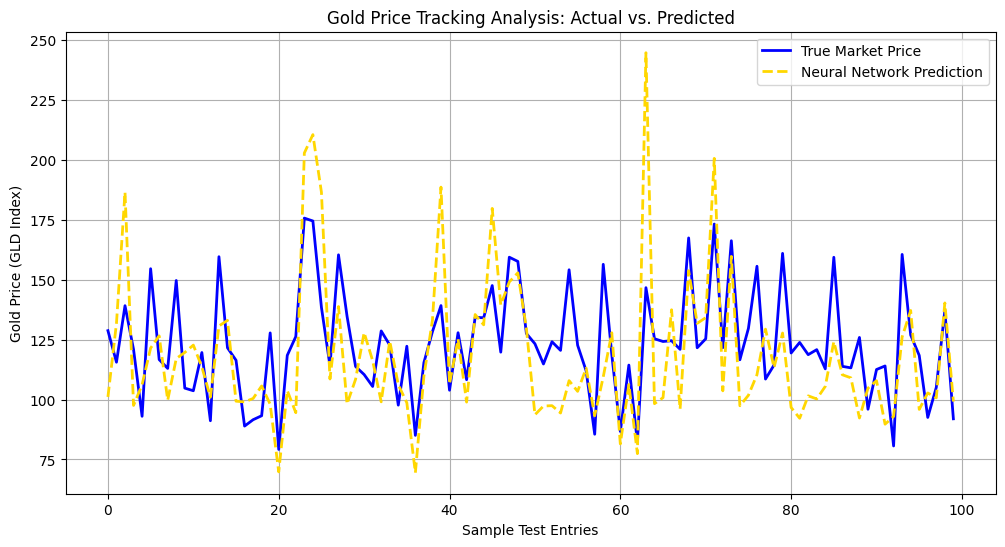

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. CRITICAL FIX: Build the 'view_results' dataframe directly inside this cell
y_pred_flat = y_pred.flatten()
y_test_reset = y_test.reset_index(drop=True)

view_results = pd.DataFrame({
    'Actual Gold Price': y_test_reset,
    'Predicted Gold Price': y_pred_flat
})

# 2. Print the first 10 rows to your console so you can see the text values
print("--- REAL VS PREDICTED VALUES ---")
print(view_results.head(10).to_string(index=False))

# 3. Plot the data visualization map using your design format
plt.figure(figsize=(12, 6))
plt.plot(view_results['Actual Gold Price'].head(100), label='True Market Price', color='blue', linewidth=2)
plt.plot(view_results['Predicted Gold Price'].head(100), label='Neural Network Prediction', color='gold', linestyle='--', linewidth=2)

plt.title('Gold Price Tracking Analysis: Actual vs. Predicted')
plt.xlabel('Sample Test Entries')
plt.ylabel('Gold Price (GLD Index)')
plt.legend()
plt.grid(True)
plt.show()
